<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/3_Transfer_Learning_Shershov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 3. Transfer Learning

Использовать предварительно обученную на ImageNet свёрточную сеть ResNet50 для классификации изображений из набора данных Oxford-IIIT Pet. Использовать изображения кошек и собак — всего 37 пород.

In [ ]:
import os

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.keras.utils.set_random_seed(42)

AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
data_dir = os.path.join(os.getcwd(), "tensorflow_datasets")
os.makedirs(data_dir, exist_ok=True)

dataset_root = os.path.join(data_dir, "oxford_iiit_pet")
dataset_dir = os.path.join(dataset_root, "4.0.0")
dataset_info_path = os.path.join(dataset_dir, "dataset_info.json")

if os.path.isdir(dataset_root) and not os.path.isfile(dataset_info_path):
    import shutil
    shutil.rmtree(dataset_root)

(train_raw, validation_raw, test_raw), info = tfds.load(
    "oxford_iiit_pet",
    split=["train[:85%]", "train[85%:]", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=True,
    data_dir=data_dir
)

class_names = info.features["label"].names
NUM_CLASSES = len(class_names)

print("Количество классов:", NUM_CLASSES)
print("Классы:", class_names)

Количество классов: 37
Классы: ['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll', 'Russian_Blue', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'Siamese', 'Sphynx', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

def preprocess(sample):
    image = tf.image.resize(sample["image"], (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    label = tf.cast(sample["label"], tf.int64)
    return image, label

def prepare(data_set, shuffle=False):
    data_set = data_set.map(preprocess, num_parallel_calls=AUTOTUNE)

    if shuffle:
        data_set = data_set.shuffle(
            1000,
            seed=42,
            reshuffle_each_iteration=True
        )

    data_set = data_set.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return data_set

train_ds = prepare(train_raw, shuffle=True)
validation_ds = prepare(validation_raw)
test_ds = prepare(test_raw)

In [ ]:
base_model = ResNet50(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [ ]:
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_layer")

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)

x = preprocess_input(x)
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="output_layer"
)(x)

resnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="resnet50_transfer_learning"
)

resnet_model.summary()

Model: "resnet50_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ random_flip (RandomFlip)      │ (None, 224, 224, 3)       │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ random_rotation               │ (None, 224, 224, 3)       │               0 │ random_flip[0][0]          │
│ (RandomRotation)              │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ random_zoom (RandomZoom)      │ (None, 224, 224, 3)       │               0 │ random_rotation[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ random_zoom[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ random_zoom[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ random_zoom[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ resnet50 (Functional)         │ (None, 7, 7, 2048)        │      23,587,712 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 2048)              │               0 │ resnet50[0][0]             │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │         262,272 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 128)               │             512 │ dense[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_layer (Dense)          │ (None, 37)                │           4,77

 Total params: 23,855,269 (91.00 MB)

 Trainable params: 267,301 (1.02 MB)

 Non-trainable params: 23,587,968 (89.98 MB)

In [ ]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model_dir = os.path.join(os.getcwd(), "Models")
os.makedirs(model_dir, exist_ok=True)

CHECKPOINT_PATH = os.path.join(model_dir, "best_resnet50_pets.keras")

lr_scheduler = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = callbacks.ModelCheckpoint(
    filepath=CHECKPOINT_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callback_list = [
    lr_scheduler,
    early_stopping,
    model_checkpoint
]

In [ ]:
EPOCHS = 1000

history = resnet_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=callback_list,
    shuffle=False,
    verbose=1
)

Epoch 1/1000
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 804ms/step - accuracy: 0.6276 - loss: 1.3536
Epoch 1: val_loss improved from None to 0.55151, saving model to C:\Users\Formoza 44-88-44\Desktop\Models\best_resnet50_pets.keras

Epoch 1: finished saving model to C:\Users\Formoza 44-88-44\Desktop\Models\best_resnet50_pets.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 98s 964ms/step - accuracy: 0.6276 - loss: 1.3536 - val_accuracy: 0.8333 - val_loss: 0.5515 - learning_rate: 0.0010
Epoch 2/1000
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 803ms/step - accuracy: 0.8907 - loss: 0.3722
Epoch 2: val_loss improved from 0.55151 to 0.44222, saving model to C:\Users\Formoza 44-88-44\Desktop\Models\best_resnet50_pets.keras

Epoch 2: finished saving model to C:\Users\Formoza 44-88-44\Desktop\Models\best_resnet50_pets.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 94s 955ms/step - accuracy: 0.8907 - loss: 0.3722 - val_accuracy: 0.8605 - val_loss: 0.4422 - learning_rate: 0.0010
Epoch 3/1000
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 844ms/step - accuracy: 0.9169 

In [ ]:
best_model = tf.keras.models.load_model(CHECKPOINT_PATH)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

115/115 ━━━━━━━━━━━━━━━━━━━━ 93s 795ms/step - accuracy: 0.8765 - loss: 0.4639
Test loss: 0.46390777826309204
Test accuracy: 0.8765330910682678


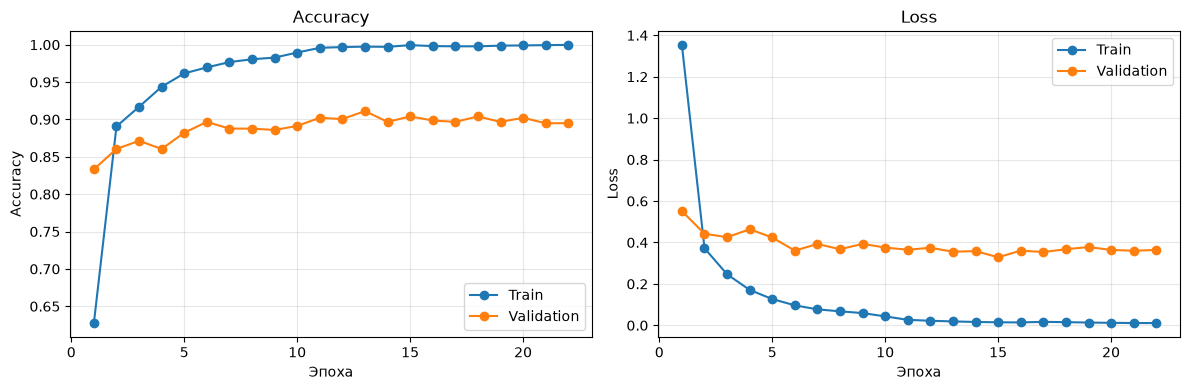

In [ ]:
import matplotlib.pyplot as plt

epochs = list(range(1, 23))

train_accuracy = [0.6276, 0.8907, 0.9169, 0.9437, 0.9616, 0.9696, 0.9767, 0.9805, 0.9827, 0.9895, 0.9958, 0.9968, 0.9974, 0.9971, 0.9994, 0.9981, 0.9978, 0.9978, 0.9987, 0.999, 0.9994, 0.9997]
validation_accuracy = [0.8333, 0.8605, 0.8714, 0.8605, 0.8822, 0.8967, 0.8877, 0.8877, 0.8859, 0.8913, 0.9022, 0.9004, 0.9112, 0.8967, 0.904, 0.8986, 0.8967, 0.904, 0.8967, 0.9022, 0.8949, 0.8949]
train_loss = [1.3536, 0.3722, 0.2465, 0.171, 0.1268, 0.0966, 0.0771, 0.0677, 0.0591, 0.0432, 0.0266, 0.0221, 0.0189, 0.0163, 0.0147, 0.014, 0.0169, 0.0153, 0.0135, 0.0121, 0.0111, 0.0111]
validation_loss = [0.5515, 0.4422, 0.4254, 0.4636, 0.424, 0.3607, 0.3927, 0.3675, 0.3931, 0.3754, 0.3648, 0.3744, 0.3553, 0.3584, 0.3286, 0.3605, 0.3539, 0.3675, 0.3778, 0.3641, 0.3599, 0.364]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, marker="o", label="Train")
plt.plot(epochs, validation_accuracy, marker="o", label="Validation")
plt.title("Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, marker="o", label="Train")
plt.plot(epochs, validation_loss, marker="o", label="Validation")
plt.title("Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

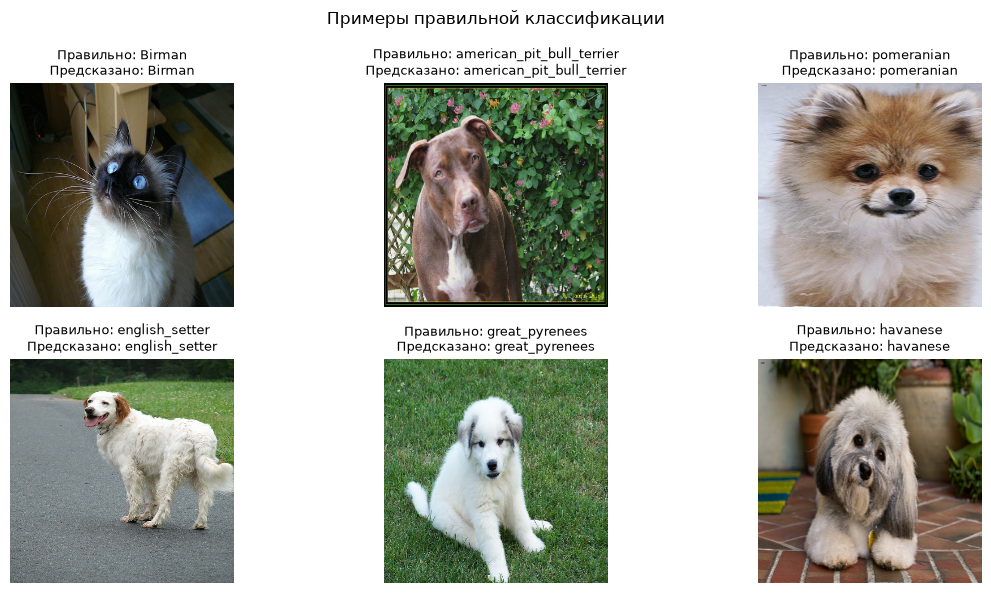

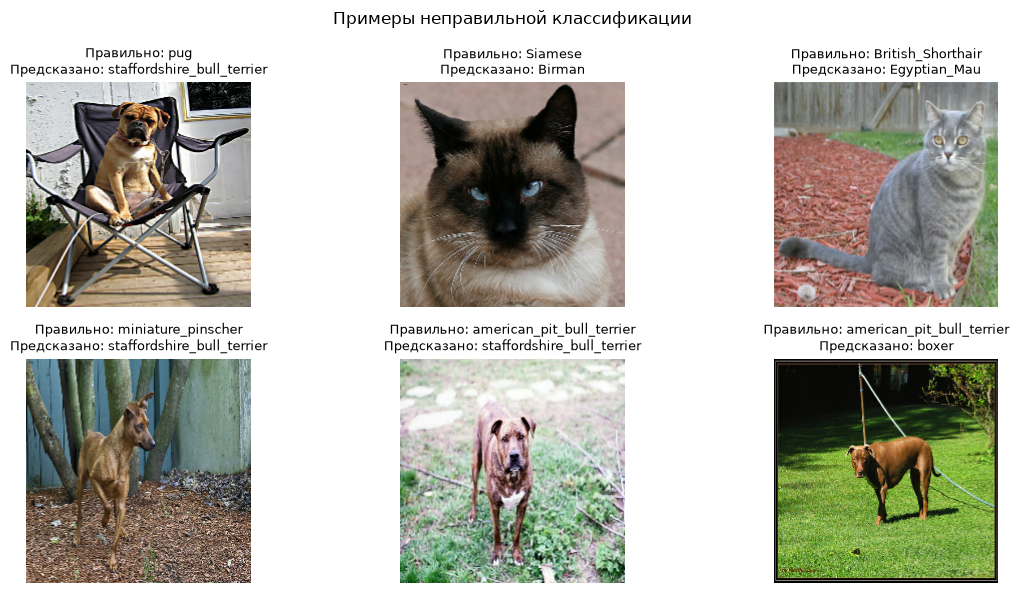

Правильных примеров: 6
Неправильных примеров: 6


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

correct_examples = []
wrong_examples = []

for images, labels in test_ds.take(10):
    predictions = best_model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)
    true_labels = labels.numpy()

    for image, true_label, predicted_label in zip(
        images.numpy(), true_labels, predicted_labels
    ):
        example = (image, int(true_label), int(predicted_label))

        if true_label == predicted_label and len(correct_examples) < 6:
            correct_examples.append(example)

        if true_label != predicted_label and len(wrong_examples) < 6:
            wrong_examples.append(example)

    if len(correct_examples) == 6 and len(wrong_examples) == 6:
        break

if correct_examples:
    plt.figure(figsize=(12, 6))

    for i, (image, true_label, predicted_label) in enumerate(correct_examples):
        plt.subplot(2, 3, i + 1)
        plt.imshow(np.clip(image, 0, 255).astype("uint8"))
        plt.title(
            f"Правильно: {class_names[true_label]}\n"
            f"Предсказано: {class_names[predicted_label]}",
            fontsize=9
        )
        plt.axis("off")

    plt.suptitle("Примеры правильной классификации")
    plt.tight_layout()
    plt.show()

if wrong_examples:
    plt.figure(figsize=(12, 6))

    for i, (image, true_label, predicted_label) in enumerate(wrong_examples):
        plt.subplot(2, 3, i + 1)
        plt.imshow(np.clip(image, 0, 255).astype("uint8"))
        plt.title(
            f"Правильно: {class_names[true_label]}\n"
            f"Предсказано: {class_names[predicted_label]}",
            fontsize=9
        )
        plt.axis("off")

    plt.suptitle("Примеры неправильной классификации")
    plt.tight_layout()
    plt.show()

print("Правильных примеров:", len(correct_examples))
print("Неправильных примеров:", len(wrong_examples))